
# Apprentissage par Transfert en Deep Learning

L'apprentissage par transfert est une technique en deep learning qui consiste à utiliser un modèle pré-entraîné sur une tâche et à le réutiliser pour une nouvelle tâche. Cela permet d'accélérer l'entraînement et de tirer parti de grands ensembles de données sur lesquels le modèle a déjà été entraîné.



## Objectifs
1. Comprendre le concept d'apprentissage par transfert.
2. Appliquer des modèles pré-entraînés pour résoudre de nouveaux problèmes.
3. Explorer l'architecture des modèles pré-entraînés populaires comme VGG16, ResNet, et YOLO.


## Architectures de Modèles Pré-entraînés

### 1. VGG16
VGG16 est un modèle de convolution profonde constitué de 16 couches, principalement des couches convolutives et des couches fully connected. Ce modèle est réputé pour sa simplicité d'architecture et est souvent utilisé comme base dans l'apprentissage par transfert.
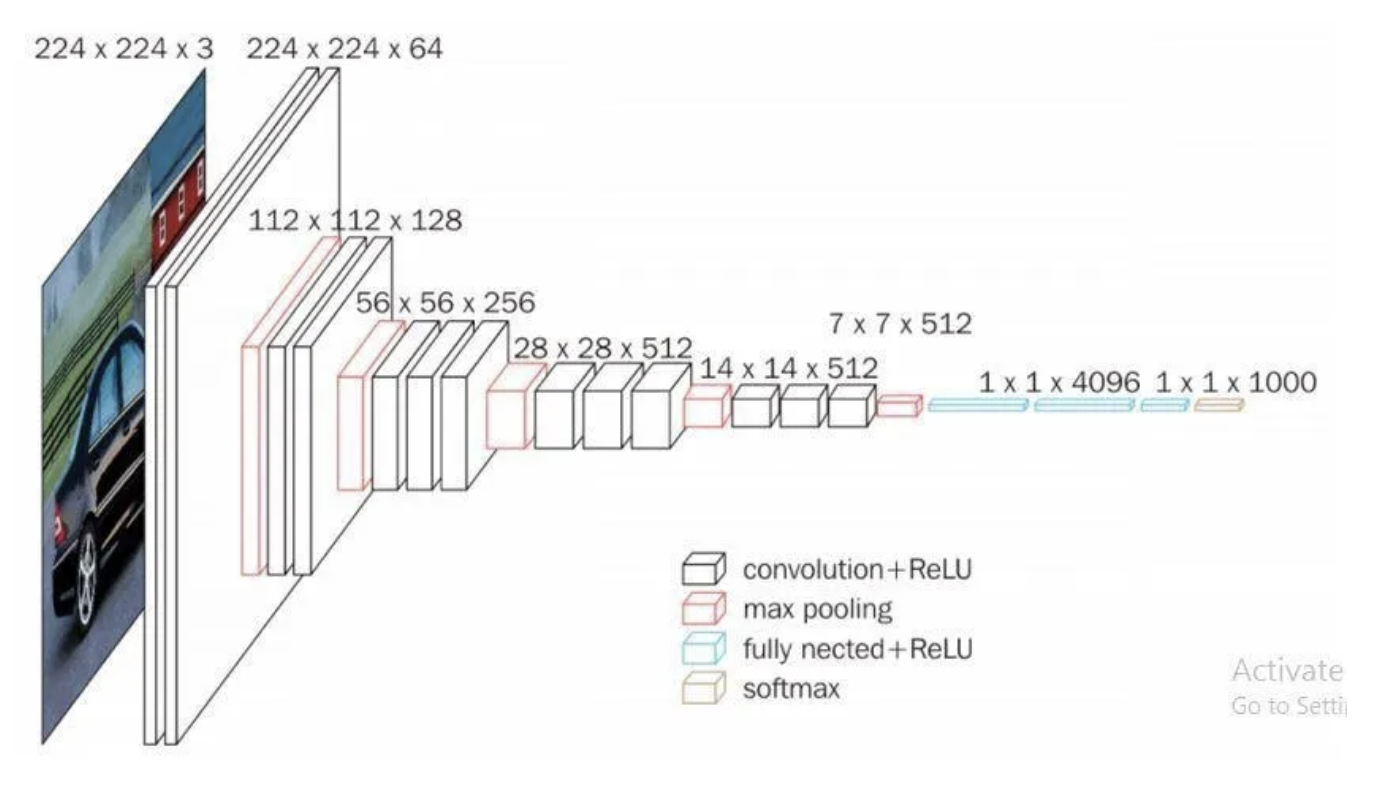




- VGG16 a 16 couches avec des poids, incluant 13 couches convolutives et 3 couches fully connected.
- L'entrée est un tenseur de dimension 224x224 avec 3 canaux (RVB).
- Il utilise des convolutions de filtres 3x3 avec un stride de 1 et des couches de maxpool 2x2 avec un stride de 2 de manière cohérente.
- Les convolutions augmentent progressivement le nombre de filtres : 64 dans Conv-1, 128 dans Conv-2, 256 dans Conv-3, et 512 dans Conv-4 et Conv-5.
- Les 3 couches fully connected comprennent deux couches de 4096 unités et une dernière pour classifier 1000 classes via softmax.





### 2. ResNet
ResNet, ou **Residual Networks**, est une architecture profonde qui a résolu le problème de la dégradation des gradients dans les réseaux très profonds grâce à des connexions résiduelles, permettant au modèle d'apprendre des représentations plus efficaces.

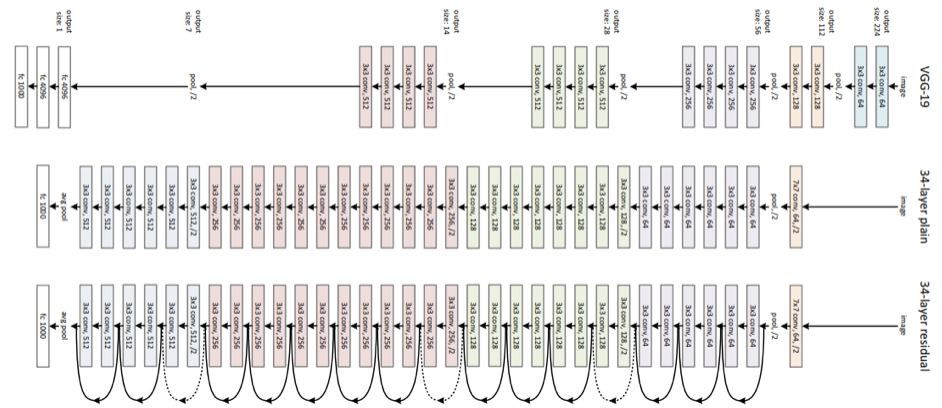

Ce réseau utilise une architecture de réseau simple à 34 couches inspirée du VGG-19, dans laquelle la connexion de raccourci est ensuite ajoutée. Ces connexions raccourcies transforment alors l'architecture en un réseau résiduel.

### 3. YOLO (You Only Look Once)
YOLO est un modèle de détection d'objets en temps réel. Contrairement à d'autres modèles, il divise l'image en une grille et prédit simultanément les bounding boxes et les probabilités pour chaque région, ce qui permet des prédictions rapides.





## Exemples Pratiques

### Exemple 1 : Classifier des Images de Chiens et de Chats avec VGG16


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import VGG16
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Charger et prétraiter les données CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0  # Normalisation
y_train, y_test = to_categorical(y_train), to_categorical(y_test)  # One-hot encoding


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 13s 0us/step


In [ ]:
# Charger le modèle pré-entraîné VGG16
base_model = VGG16(weights='imagenet', include_top=False, input_shape=(32, 32, 3))

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


In [ ]:
# Geler les couches du modèle de base
for layer in base_model.layers:
    layer.trainable = False

In [ ]:
# Ajouter des couches personnalisées
model = Sequential([
    base_model,
    Flatten(),
    Dense(128, activation='relu'),
    Dense(10, activation='softmax')  # 10 classes pour CIFAR-10
])


In [ ]:
# Compiler le modèle
model.compile(optimizer='sgd', loss='categorical_crossentropy', metrics=['accuracy'])

# Entraîner le modèle et stocker l'historique
history = model.fit(x_train, y_train, epochs=20, batch_size=100, validation_data=(x_test, y_test))

# Évaluation du modèle
test_loss, test_acc = model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc}")



Epoch 1/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 20s 33ms/step - accuracy: 0.3355 - loss: 1.9465 - val_accuracy: 0.3990 - val_loss: 1.7442
Epoch 2/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.4458 - loss: 1.6406 - val_accuracy: 0.4535 - val_loss: 1.5790
Epoch 3/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.4793 - loss: 1.5243 - val_accuracy: 0.4769 - val_loss: 1.5045
Epoch 4/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.4984 - loss: 1.4600 - val_accuracy: 0.4985 - val_loss: 1.4504
Epoch 5/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.5126 - loss: 1.4169 - val_accuracy: 0.5064 - val_loss: 1.4218
Epoch 6/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - accuracy: 0.5210 - loss: 1.3859 - val_accuracy: 0.5137 - val_loss: 1.3961
Epoch 7/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 22ms/step - accuracy: 0.5284 - loss: 1.3604 - val_accuracy: 0.5241 - val_loss: 1.3706
Epoch 8/20
500/500 ━━━━━━━━━━━━━━━━━━━━ 11s 23ms/step - accuracy: 0.5338 - loss: 1.3398 - 

In [ ]:
# Matrice de confusion
y_pred = model.predict(x_test)
y_pred_classes = y_pred.argmax(axis=1)
y_true = y_test.argmax(axis=1)

conf_matrix = confusion_matrix(y_true, y_pred_classes)

313/313 [==============================] - 26s 83ms/step


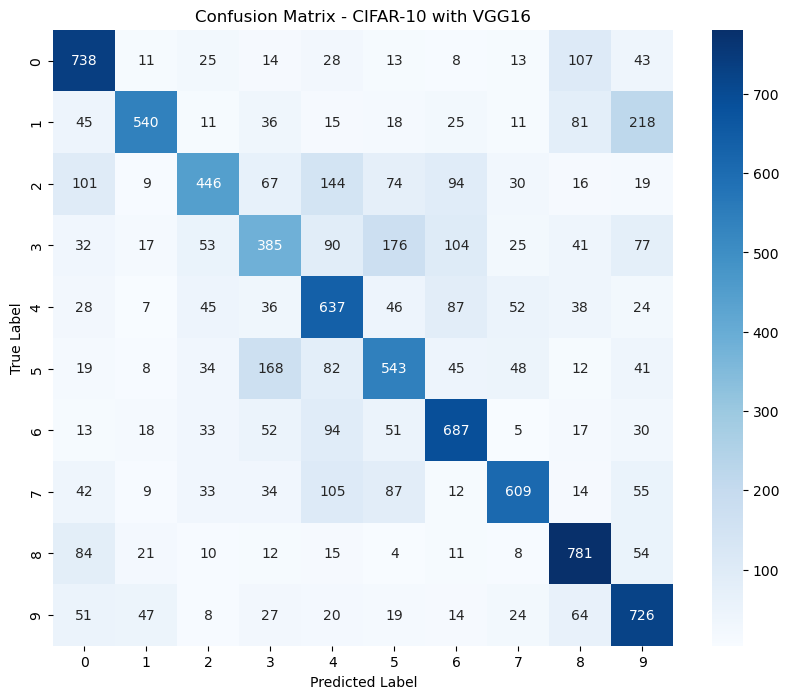

In [ ]:
# Afficher la matrice de confusion
plt.figure(figsize=(10, 8))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix - CIFAR-10 with VGG16')
plt.show()

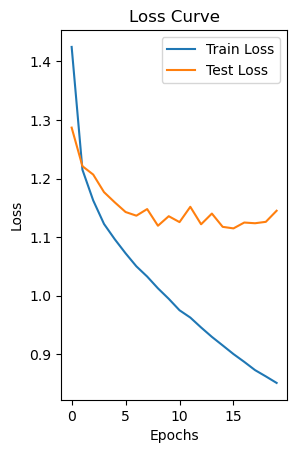

In [ ]:
# Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Loss Curve')
plt.legend()


## Fine tuning du modele VGG16

In [ ]:

# Chargement CIFAR-10
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalisation de base en float32
x_train = x_train.astype("float32")
x_test = x_test.astype("float32")

# Labels one-hot
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

print(x_train.shape, x_test.shape)

(50000, 32, 32, 3) (10000, 32, 32, 3)


In [ ]:
from tensorflow.keras.applications.vgg16 import preprocess_input

BATCH_SIZE = 32

def preprocess(image, label):
    image = tf.image.resize(image, (224, 224))   # resize image par image
    image = preprocess_input(image)              # prétraitement VGG16
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train))
train_ds = train_ds.shuffle(10000).map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((x_test, y_test))
test_ds = test_ds.map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [ ]:
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# Base VGG16
base_model = VGG16(weights="imagenet", include_top=False, input_shape=(224, 224, 3))

# On gèle presque tout
for layer in base_model.layers[:-4]:
    layer.trainable = False

for layer in base_model.layers[-4:]:
    layer.trainable = True

# Modèle final
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(256, activation="relu"),
    Dropout(0.5),
    Dense(10, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    verbose=1
)

history = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=5,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print("Test accuracy :", test_acc)

Epoch 1/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 426s 260ms/step - accuracy: 0.7779 - loss: 0.6737 - val_accuracy: 0.8778 - val_loss: 0.3798 - learning_rate: 1.0000e-04
Epoch 2/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 393s 252ms/step - accuracy: 0.9052 - loss: 0.2927 - val_accuracy: 0.9033 - val_loss: 0.2978 - learning_rate: 1.0000e-04
Epoch 3/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 465s 266ms/step - accuracy: 0.9382 - loss: 0.1889 - val_accuracy: 0.9096 - val_loss: 0.2941 - learning_rate: 1.0000e-04
Epoch 4/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 393s 251ms/step - accuracy: 0.9575 - loss: 0.1292 - val_accuracy: 0.9100 - val_loss: 0.3016 - learning_rate: 1.0000e-04
Epoch 5/5
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 0s 214ms/step - accuracy: 0.9691 - loss: 0.0907
Epoch 5: ReduceLROnPlateau reducing learning rate to 4.999999873689376e-05.
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 417s 266ms/step - accuracy: 0.9698 - loss: 0.0903 - val_accuracy: 0.9126 - val_loss: 0.3183 - learning_rate: 1.0000e-04
Test accuracy : 0.909600019454956
